# discovery_auc — does a stress runway flag defaulters better than the judge runway?
682 loan accounts, 76 defaults. Two views:
- **(b) pre-loan only — the clean test.** Only months before the loan was granted, so we use only what the bank knew at the time.
- **(a) full history — leaky.** Status D means "currently in debt", so the final balances already show the trouble. Shown for reference only.

AUC = probability that a random defaulter scores riskier than a random non-defaulter (0.5 = coin flip).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
BLUE, GREY, RED = "#2a6fdb", "#9aa0a6", "#c2410c"

# repo root = first folder upward that contains Tangerine/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Tangerine").exists())
DATA = ROOT / "Tangerine" / "data"
WORK = ROOT / "work"


def run_notebook(path):
    """Execute another notebook's code cells in this namespace (skips cells tagged # skip-on-import)."""
    cells = json.loads(Path(path).read_text(encoding="utf-8"))["cells"]
    for c in cells:
        src = "".join(c["source"])
        if c["cell_type"] == "code" and "# skip-on-import" not in src:
            exec(src, globals())

run_notebook(WORK / "engine.ipynb")

## AUC + bootstrap helpers

In [2]:
def auc(score, y):
    s = pd.Series(np.asarray(score, float))
    y = pd.Series(np.asarray(y)).astype(bool)
    ok = s.notna()
    s, y = s[ok], y[ok]
    r = s.rank()
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def boot_ci(score, y, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    s, y = np.asarray(score, float), np.asarray(y, int)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(s), len(s))
        if 0 < y[i].sum() < len(i):
            vals.append(auc(s[i], y[i]))
    return np.percentile(vals, [2.5, 97.5])

assert auc([1, 2, 3, 4], [0, 0, 1, 1]) == 1.0 and auc([4, 3, 2, 1], [0, 0, 1, 1]) == 0.0

## Load data

In [3]:
ms = load_monthly()
loans = pd.read_csv(DATA / "loans.csv", parse_dates=["loan_start"])
metrics = pd.read_parquet(WORK / "metrics.parquet").set_index("account_id")
loans.status.value_counts().sort_index()

status
A    203
B     31
C    403
D     45
Name: count, dtype: int64

## Pre-loan window: judge formula applied to the months before the loan
We add the new loan payment to spending, because that's the question the bank faced: can they carry this payment?

In [4]:
x = ms.merge(loans[["account_id", "loan_start", "monthly_payment", "defaulted"]], on="account_id")
x = x[pd.to_datetime(x["month"] + "-01") < x["loan_start"].dt.to_period("M").dt.to_timestamp()]
g = x.groupby("account_id")
pre = pd.DataFrame({
    "n": g.size(),
    "I": g["money_in"].median(),
    "S": g["money_out"].median(),
    "I_p25": g["money_in"].quantile(0.25),
    "B": g["avg_daily_balance"].apply(lambda s: s.iloc[-6:].mean()),
    "cv": g["money_in"].std() / g["money_in"].mean(),
    "neg": g["days_below_zero"].sum() > 0,
    "minbal": g["min_balance"].min(),
})
pre["lean"] = (x["money_in"] < 0.55 * x["account_id"].map(pre["I"])).groupby(x["account_id"]).mean()
ln = loans.set_index("account_id")
pre["pay"] = ln["monthly_payment"].reindex(pre.index)
pre["y"] = ln["defaulted"].reindex(pre.index)
pre["rw_judge"] = runway_num(pre.B, pre.I, pre.S + pre.pay)
pre["rw_judge_ei"] = runway_num(pre.B, 0.55 * pre.I, pre.S + pre.pay)
pre["rw_stress"] = runway_num(pre.B, pre.I_p25, pre.S + pre.pay)
pre["pti"] = pre.pay / pre.I
pre["buf_mo"] = pre.B / pre.S
print(f"{len(pre)} loans, pre-loan months median {pre.n.median():.0f} (min {pre.n.min()}), defaults {int(pre.y.sum())}")
pre.head()

682 loans, pre-loan months median 13 (min 3), defaults 76


,n,I,S,I_p25,B,cv,neg,minbal,lean,pay,y,rw_judge,rw_judge_ei,rw_stress,pti,buf_mo
account_id,,,,,,,,,,,,,,,,
20111,13,19690.860,10014.590,503.420,38893.030000,1.000742,False,503.42,0.384615,2330.19,1,120.0,25.7,3.3,0.118339,3.883637
20134,4,7932.705,975.370,5989.220,10915.415000,0.668943,False,188.78,0.250000,1312.03,0,120.0,120.0,120.0,0.165395,11.191051
20143,10,30832.340,28715.975,30824.975,28899.571667,0.380427,False,692.20,0.100000,5119.74,0,9.6,1.7,9.6,0.166051,1.006394
20208,13,16906.540,13340.520,5089.030,13480.373333,0.842044,False,440.49,0.461538,1355.45,0,120.0,2.5,1.4,0.080173,1.010483
20331,16,1652.555,9956.185,153.980,14059.928333,1.276156,True,-452.19,0.437500,4555.91,1,1.1,1.0,1.0,2.756889,1.412180


## (b) AUC on pre-loan data (clean)
We flip the sign of runway and buffer so that a higher score always means riskier.

In [5]:
scores_pre = {
    "judge runway (median I, +loan pmt)": -pre.rw_judge,
    "judge EI runway (+loan pmt)": -pre.rw_judge_ei,
    "stress runway (p25 income, +loan pmt)": -pre.rw_stress,
    "buffer in months of spending": -pre.buf_mo,
    "income CV (volatility)": pre.cv,
    "lean-month share": pre.lean,
    "payment / income": pre.pti,
    "lowest balance (negated)": -pre.minbal,
    "ever negative (0/1)": pre.neg.astype(float),
}
combo = (pre.cv.rank(pct=True) + (-pre.rw_stress).rank(pct=True) + pre.pti.rank(pct=True)) / 3
scores_pre["COMBO rank-avg(CV, stress rw, PTI)"] = combo

res = pd.DataFrame([(k, auc(s, pre.y), *boot_ci(s, pre.y)) for k, s in scores_pre.items()],
                   columns=["score", "AUC", "lo", "hi"]).set_index("score").round(3)
res.sort_values("AUC")

,AUC,lo,hi
score,,,
buffer in months of spending,0.593,0.508,0.676
"judge runway (median I, +loan pmt)",0.639,0.563,0.713
judge EI runway (+loan pmt),0.665,0.587,0.739
payment / income,0.667,0.601,0.733
ever negative (0/1),0.678,0.621,0.733
lowest balance (negated),0.681,0.600,0.755
income CV (volatility),0.712,0.654,0.771
lean-month share,0.716,0.656,0.775
"stress runway (p25 income, +loan pmt)",0.752,0.684,0.817


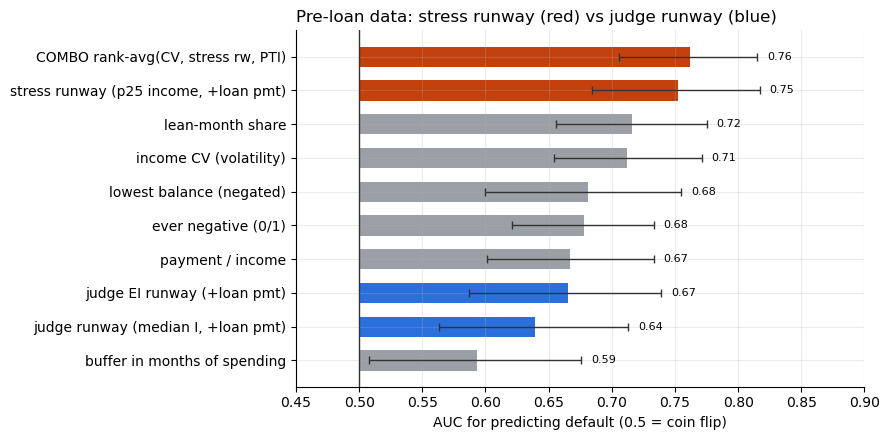

In [6]:
r = res.sort_values("AUC")
colors = [RED if "stress" in k else BLUE if "judge" in k else GREY for k in r.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(r.index, r.AUC - 0.5, left=0.5, color=colors, height=0.6)
ax.errorbar(r.AUC, r.index, xerr=[r.AUC - r.lo, r.hi - r.AUC], fmt="none", ecolor="#333", capsize=3, lw=1)
ax.axvline(0.5, color="#333", lw=1)
ax.set(xlim=(0.45, 0.9), xlabel="AUC for predicting default (0.5 = coin flip)")
ax.set_title("Pre-loan data: stress runway (red) vs judge runway (blue)", loc="left")
for i, (v, hi) in enumerate(zip(r.AUC, r.hi)):
    ax.text(hi + 0.008, i, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout()

## Paired bootstrap: is the gap real?
We resample the same loans for both scores in each draw, so the difference gets a proper confidence interval.

In [7]:
rng = np.random.default_rng(1)
a_s, a_j, a_b, y = (-pre.rw_stress).values, (-pre.rw_judge).values, (-pre.buf_mo).values, pre.y.values
d_sj, d_sb = [], []
for _ in range(2000):
    i = rng.integers(0, len(y), len(y))
    d_sj.append(auc(a_s[i], y[i]) - auc(a_j[i], y[i]))
    d_sb.append(auc(a_s[i], y[i]) - auc(a_b[i], y[i]))
pd.DataFrame({name: {"mean diff": np.mean(d), "CI lo": np.percentile(d, 2.5), "CI hi": np.percentile(d, 97.5),
                     "P(diff<=0)": np.mean(np.array(d) <= 0)}
              for name, d in [("stress - judge runway", d_sj), ("stress - buffer months", d_sb)]}).T.round(3)

,mean diff,CI lo,CI hi,P(diff<=0)
stress - judge runway,0.113,0.049,0.179,0.0
stress - buffer months,0.157,0.078,0.241,0.0


## Default rate by quartile (the pitch chart)

In [8]:
pre["cv_q"] = pd.qcut(pre.cv, 4, labels=["Q1 steady", "Q2", "Q3", "Q4 volatile"])
pre["rw_q"] = pd.qcut(pre.rw_judge_ei.rank(method="first"), 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])
pre["st_q"] = pd.qcut(pre.rw_stress.rank(method="first"), 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])
quart = {name: pre.groupby(col, observed=True)["y"].agg(loans="count", defaults="sum", rate="mean")
         for col, name in [("cv_q", "income volatility"), ("rw_q", "judge EI runway"), ("st_q", "stress runway")]}
pd.concat(quart, axis=1).round(3)

income volatility                 judge EI runway                 stress runway                
                        loans defaults   rate           loans defaults   rate         loans defaults   rate
Q1 steady               171.0      7.0  0.041             NaN      NaN    NaN           NaN      NaN    NaN
Q2                      170.0      8.0  0.047           170.0     11.0  0.065         170.0     16.0  0.094
Q3                      170.0     22.0  0.129           170.0     13.0  0.076         170.0      5.0  0.029
Q4 volatile             171.0     39.0  0.228             NaN      NaN    NaN           NaN      NaN    NaN
Q1 shortest               NaN      NaN    NaN           171.0     39.0  0.228         171.0     46.0  0.269
Q4 longest                NaN      NaN    NaN           171.0     13.0  0.076         171.0      9.0  0.053

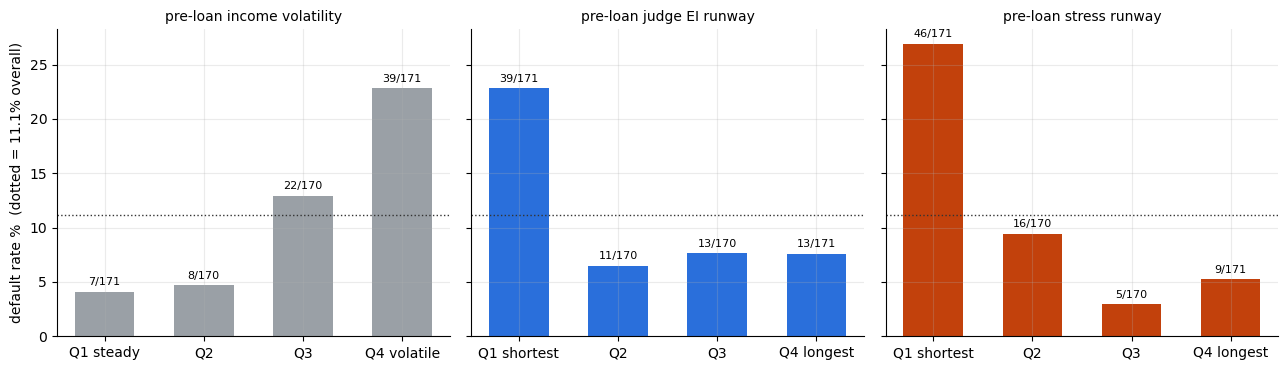

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, t) in zip(axes, quart.items()):
    bars = ax.bar(t.index.astype(str), 100 * t.rate, color=RED if name == "stress runway" else BLUE if "judge" in name else GREY, width=0.6)
    for b, (d, n) in zip(bars, zip(t.defaults, t.loans)):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6, f"{d}/{n}", ha="center", fontsize=8)
    ax.axhline(100 * pre.y.mean(), color="#333", lw=1, ls=":")
    ax.set_title(f"pre-loan {name}", fontsize=10)
axes[0].set_ylabel("default rate %  (dotted = 11.1% overall)")
plt.tight_layout()

## (a) Full history — leaky, for reference only

In [10]:
L = metrics[metrics.has_loan]
scores_full = {
    "judge runway (no shock)": -L.rw_base,
    "judge EI runway": -L.rw_ei55,
    "stress runway (p25 income)": -L.rw_stress_p25,
    "income CV": L.income_cv,
    "lean-month share": L.lean_share,
    "payment / income": L.payment_to_income,
}
pd.Series({k: auc(s, L.defaulted) for k, s in scores_full.items()}, name="AUC (leaky)").round(3)

judge runway (no shock)       0.658
judge EI runway               0.724
stress runway (p25 income)    0.768
income CV                     0.740
lean-month share              0.702
payment / income              0.715
Name: AUC (leaky), dtype: float64

## Save pre-loan features

In [11]:
pre.drop(columns=["cv_q", "rw_q", "st_q"]).to_parquet(WORK / "preloan_features.parquet")
print("saved", pre.shape)

saved (682, 19)
